# Synthetic streams and drift

`fl.synth.MultiTarget` generates multi-target regression streams whose properties you control:
how correlated the outputs are, how noisy and how nonlinear each one is, and when each one
drifts. This notebook uses it to look at a situation that only exists with several outputs: one
output drifts while the others do not, and the budget has to decide whether to follow it.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from river import multioutput, neighbors

import fishladder as fl

## The generator

Each output is the sum of a function shared by all outputs, a function of its own, and noise.
`correlation` sets how much of each output comes from the shared function. The functions all
have unit variance, so `noise` is relative to the signal. Like River's synthetic datasets, the
stream is infinite, and `take` gives its first instances.

In [2]:
dataset = fl.synth.MultiTarget(
    n_features=3,
    correlation=0.5,
    noise={"y0": 0.1, "y1": 0.1, "y2": 1.0},
    seed=0,
)
x, y = next(iter(dataset))
x, y

({0: 0.38213610129812814, 1: 0.5477490601669164, 2: 0.4114381378494729},
 {'y0': -0.10922900838630473,
  'y1': 0.3466870743349819,
  'y2': -1.9398557468021598})

In [3]:
outputs = pd.DataFrame([y for _, y in dataset.take(5000)])
outputs.corr().round(2)

,y0,y1,y2
y0,1.00,0.50,0.36
y1,0.50,1.00,0.35
y2,0.36,0.35,1.00


`y0` and `y1` share half their signal and have little noise, so they correlate at about 0.5.
`y2` is much noisier, which weakens its correlation with the others. With independent noise,
two outputs with noise $\sigma_a$ and $\sigma_b$ correlate at
$\rho / \sqrt{(1 + \sigma_a^2)(1 + \sigma_b^2)}$, about 0.35 here.

`lengthscale` sets how nonlinear the functions are, from almost linear for large values to hard
to learn for small ones, and `drift` sets when each output changes.

## One output drifts

Here, `y1` suddenly changes after 3000 instances, while `y0` and `y2` stay the same. All
outputs cost the same, and the budget allows 0.6 labels per instance, i.e. 20% of the labels.

The model is a nearest neighbours regressor per output, which only remembers the last 200
labels it learned from. It can only adapt to the drift by getting new labels for `y1`, so how
quickly it recovers depends on where the budget goes.

In [4]:
DRIFT = 3000
COSTS = {"y0": 1.0, "y1": 1.0, "y2": 1.0}


def stream(seed):
    dataset = fl.synth.MultiTarget(
        n_features=3, correlation=0.3, noise=0.1, drift={"y1": DRIFT}, seed=seed
    )
    return dataset.take(2 * DRIFT)


def knn():
    return neighbors.KNNRegressor(engine=neighbors.LazySearch(window_size=200))


def strategies(seed):
    return {
        "random": fl.strategy.RandomPerOutput(p=1.0, seed=seed),
        "expected error": fl.strategy.ExpectedError(knn()),
        "committee": fl.strategy.QueryByCommittee(knn(), seed=seed),
    }


def run(strategy, budget, seed):
    model = multioutput.PerOutputRegressor(knn())
    df = fl.evaluate.prequential(stream(seed), model, strategy, budget, COSTS).to_frame()
    df["error"] = (df["y_true"] - df["y_pred"]).abs()
    return df

We first share a single budget between the outputs. The budget manager then gives each label to
the output with the highest utility, so a strategy can move labels from one output to another.

In [5]:
shared = {
    (name, seed): run(strategy, fl.budget.RateBudget(0.6), seed)
    for seed in range(3)
    for name, strategy in strategies(seed).items()
}


def after_drift(df, n):
    return df[(df["step"] >= DRIFT) & (df["step"] < DRIFT + n)]


def summary(runs):
    rows = []
    for (name, seed), df in runs.items():
        labels = after_drift(df, 500).groupby("output")["queried"].sum()
        y1 = after_drift(df, 1000).query("output == 'y1'")
        rows.append(
            {
                "strategy": name,
                "seed": seed,
                "share of labels to y1": labels["y1"] / labels.sum(),
                "y1 MAE after drift": y1["error"].mean(),
            }
        )
    return pd.DataFrame(rows).pivot(index="strategy", columns="seed").round(2)


summary(shared)

share of labels to y1             y1 MAE after drift        \
seed                               0     1     2                  0     1   
strategy                                                                    
committee                       0.33  0.50  0.48               0.61  0.38   
expected error                  0.64  0.69  0.72               0.49  0.34   
random                          0.33  0.33  0.33               0.58  0.47   

                      
seed               2  
strategy              
committee       0.48  
expected error  0.40  
random          0.58

For each stream, the table shows the share of labels that went to `y1` in the 500 instances
after the drift, and the error on `y1` in the 1000 instances after it. Random querying keeps
giving `y1` a third of the labels. Expected error notices that the model got worse on `y1` and
moves most of the labels there, so `y1` recovers faster on every stream.

The committee reacts less, and not on every stream. It measures how much its members disagree,
not how wrong they are: right after the drift, they all learned the old concept and agree on
it. They only start to disagree once new labels for `y1` come in.

Here is how the labels and the error on `y1` evolve on the first stream:

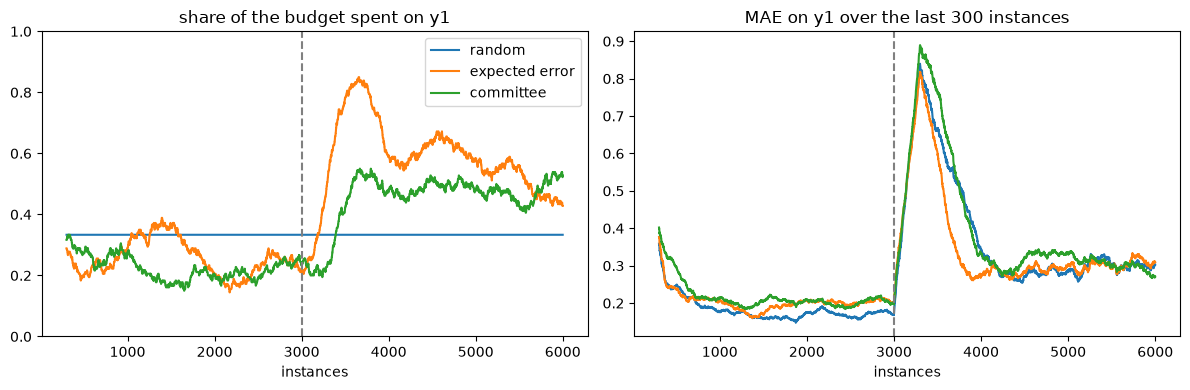

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in strategies(seed=0):
    y1 = shared[name, 0].query("output == 'y1'").set_index("step")
    axes[0].plot(y1["queried"].rolling(300).sum() / (0.6 * 300), label=name)
    axes[1].plot(y1["error"].rolling(300).mean(), label=name)
for ax in axes:
    ax.axvline(DRIFT, color="grey", linestyle="--")
    ax.set_xlabel("instances")
axes[0].set(title="share of the budget spent on y1", ylim=(0, 1))
axes[1].set(title="MAE on y1 over the last 300 instances")
axes[0].legend()
fig.tight_layout()

What does this cost the other outputs? Here is the error of every output over the whole stream:

In [7]:
whole = pd.DataFrame(
    [
        {"strategy": name, "seed": seed, "output": output, "MAE": error}
        for (name, seed), df in shared.items()
        for output, error in df.groupby("output")["error"].mean().items()
    ]
)
whole.pivot(index="strategy", columns=["output", "seed"], values="MAE").round(2)

output,y0,y1,y2,y0,y1,y2,y0,y1,y2
seed,0,0,0,1,1,1,2,2,2
strategy,,,,,,,,,
committee,0.25,0.32,0.25,0.25,0.28,0.24,0.31,0.30,0.20
expected error,0.26,0.29,0.25,0.25,0.28,0.21,0.30,0.31,0.21
random,0.23,0.29,0.23,0.24,0.29,0.18,0.28,0.32,0.20


Over the whole stream, the faster recovery barely shows on `y1`: it only lasts a few hundred
instances, and expected error is at most 0.01 better than random querying there. Meanwhile, it is
worse on `y0` and `y2` on every stream. Following the drift is worth it when a fast recovery
on the drifting output matters more than a small loss on the others.

## Per-output budgets

With `fl.budget.PerOutput`, each output has its own budget and cannot spend the others'. This is
what protects expensive outputs from being starved by cheap ones, as shown in the quickstart
notebook. But it also means that no strategy can move labels to the output that drifted:

In [8]:
per_output = {
    (name, seed): run(strategy, fl.budget.PerOutput(fl.budget.RateBudget(0.6)), seed)
    for seed in range(3)
    for name, strategy in strategies(seed).items()
    if name != "committee"
}
summary(per_output)

share of labels to y1             y1 MAE after drift        \
seed                               0     1     2                  0     1   
strategy                                                                    
expected error                  0.33  0.33  0.33               0.61  0.49   
random                          0.33  0.33  0.33               0.61  0.49   

                      
seed               2  
strategy              
expected error  0.54  
random          0.54

Every output gets exactly a third of the labels, and expected error does exactly as well as
random querying: each output is queried as soon as its budget allows it, whatever its utility.
`fl.budget.VariableThreshold` can make a strategy pick *which instances* to label within each
output's budget, as shown in the query strategies notebook, but not move budget between
outputs.

A shared budget lets labels follow the drift, but can starve outputs; per-output budgets prevent
starvation, but cannot follow the drift. Which one fits depends on the costs and on how the
outputs are expected to change.